# Notebook 02: our algorithm (RH-STA*)
Risk-aware receding-horizon space-time A* with a 2-opt coin tour.

| Part | What it does | Fixes |
|---|---|---|
| Coin tour | nearest neighbour + 2-opt from the character's real position, rebuilt when coins change | L3, L7 |
| Space-time A* | state is (x, y, t). Moves: 16 directions x 3 step sizes, step onto the goal, or wait. Each move is checked against where the hazards will be at that time | L1, L4 |
| Hazard prediction | fires: exact, because their paths are fixed in `cointex.kv`. Monsters: current velocity + a margin that grows the further ahead we look | L1, L2 |
| Re-planning | only do the first move, then look again and re-plan every 0.25 s (no sleep) | L1, L5 |
| Fallbacks | blocked coin -> try the next one; no path -> best partial path; all moves unsafe -> move away from hazards; stuck for a long time -> accept more risk | L6 |

Cost of a move = 1 + 0.2 * length + risk_weight * near-miss risk (+ penalty for contact later in the plan).
Contact in the first 3 moves is not allowed.
Heuristic = distance left / max step, i.e. the number of moves still needed, so it never overestimates.

In [1]:
# mount google drive and make the folders we save everything into
import os, sys, json, subprocess, datetime, importlib
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive/COMP6009_Assignment-Part A'   # all our files go here
PATHS = {
    'code':         f'{ROOT}/code',                          # the cointex_parta package
    'data':         f'{ROOT}/data',                          # cointex.kv, level table
    'config':       f'{ROOT}/config',                        # experiment_config.json
    'greedy':       f'{ROOT}/results/01_greedy_baseline',
    'proposed':     f'{ROOT}/results/02_proposed',
    'ga':           f'{ROOT}/results/03_ga_task2',
    'compare':      f'{ROOT}/results/04_comparison',
    'report_figs':  f'{ROOT}/report_assets/figures',         # final figures for the report/slides
    'report_tabs':  f'{ROOT}/report_assets/tables',          # final tables for the report
    'deliverables': f'{ROOT}/deliverables',
    'logs':         f'{ROOT}/logs',
}
for p in PATHS.values():
    os.makedirs(p, exist_ok=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pygad==3.3.1'], check=True)
if PATHS['code'] not in sys.path:
    sys.path.insert(0, PATHS['code'])

def log_run(notebook, **info):
    # keep a log of every run
    info.update(notebook=notebook, at=datetime.datetime.now().isoformat(timespec='seconds'))
    with open(f"{PATHS['logs']}/run_log.jsonl", 'a') as f:
        f.write(json.dumps(info) + '\n')

print('Project root:', ROOT)

Mounted at /content/drive
Project root: /content/drive/MyDrive/COMP6009_Assignment-Part A


In [2]:
# load our code (written to drive by notebook 00) and the experiment settings
assert os.path.exists(f"{PATHS['code']}/cointex_parta/__init__.py"), \
    'code not found on Drive (notebook 00 writes it)'
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
import cointex_parta
from cointex_parta import runner, plots, sim, levels
plots.style()
CFG = json.load(open(f"{PATHS['config']}/experiment_config.json"))
LEVELS, SEEDS = CFG['levels'], list(range(CFG['n_seeds']))
WORKERS = os.cpu_count()
print(f"cointex_parta v{cointex_parta.__version__} | {len(LEVELS)} levels x {len(SEEDS)} seeds | {WORKERS} CPU workers")
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

for sub in ('figures', 'tables'): os.makedirs(f"{PATHS['proposed']}/{sub}", exist_ok=True)
from dataclasses import replace, asdict
from cointex_parta.agents.proposed import DEFAULT, VARIANTS, ProposedAgent, _fire_positions
OUT = PATHS['proposed']
print(asdict(DEFAULT))

cointex_parta v1.0.0 | 24 levels x 50 seeds | 12 CPU workers
{'name': 'proposed', 'max_step': 0.3, 'step_fracs': (1.0, 0.5, 0.25), 'n_dirs': 16, 'horizon': 8, 'max_expansions': 100, 'heuristic_weight': 1.2, 'samples': 8, 'grid': 0.02, 'use_hazards': True, 'predict_motion': True, 'monster_margin': 0.05, 'fire_margin': 0.035, 'monster_sigma': 0.1, 'contact_buffer': 0.01, 'hard_steps': 3, 'late_contact_penalty': 3.0, 'risk_weight': 4.0, 'dist_weight': 0.2, 'use_tour': True, 'two_opt': True, 'alt_goals': 3, 'defer_seconds': 1.0, 'stuck_seconds': 4.0, 'stagnation_relax': 0.25}


## 1. Flowchart

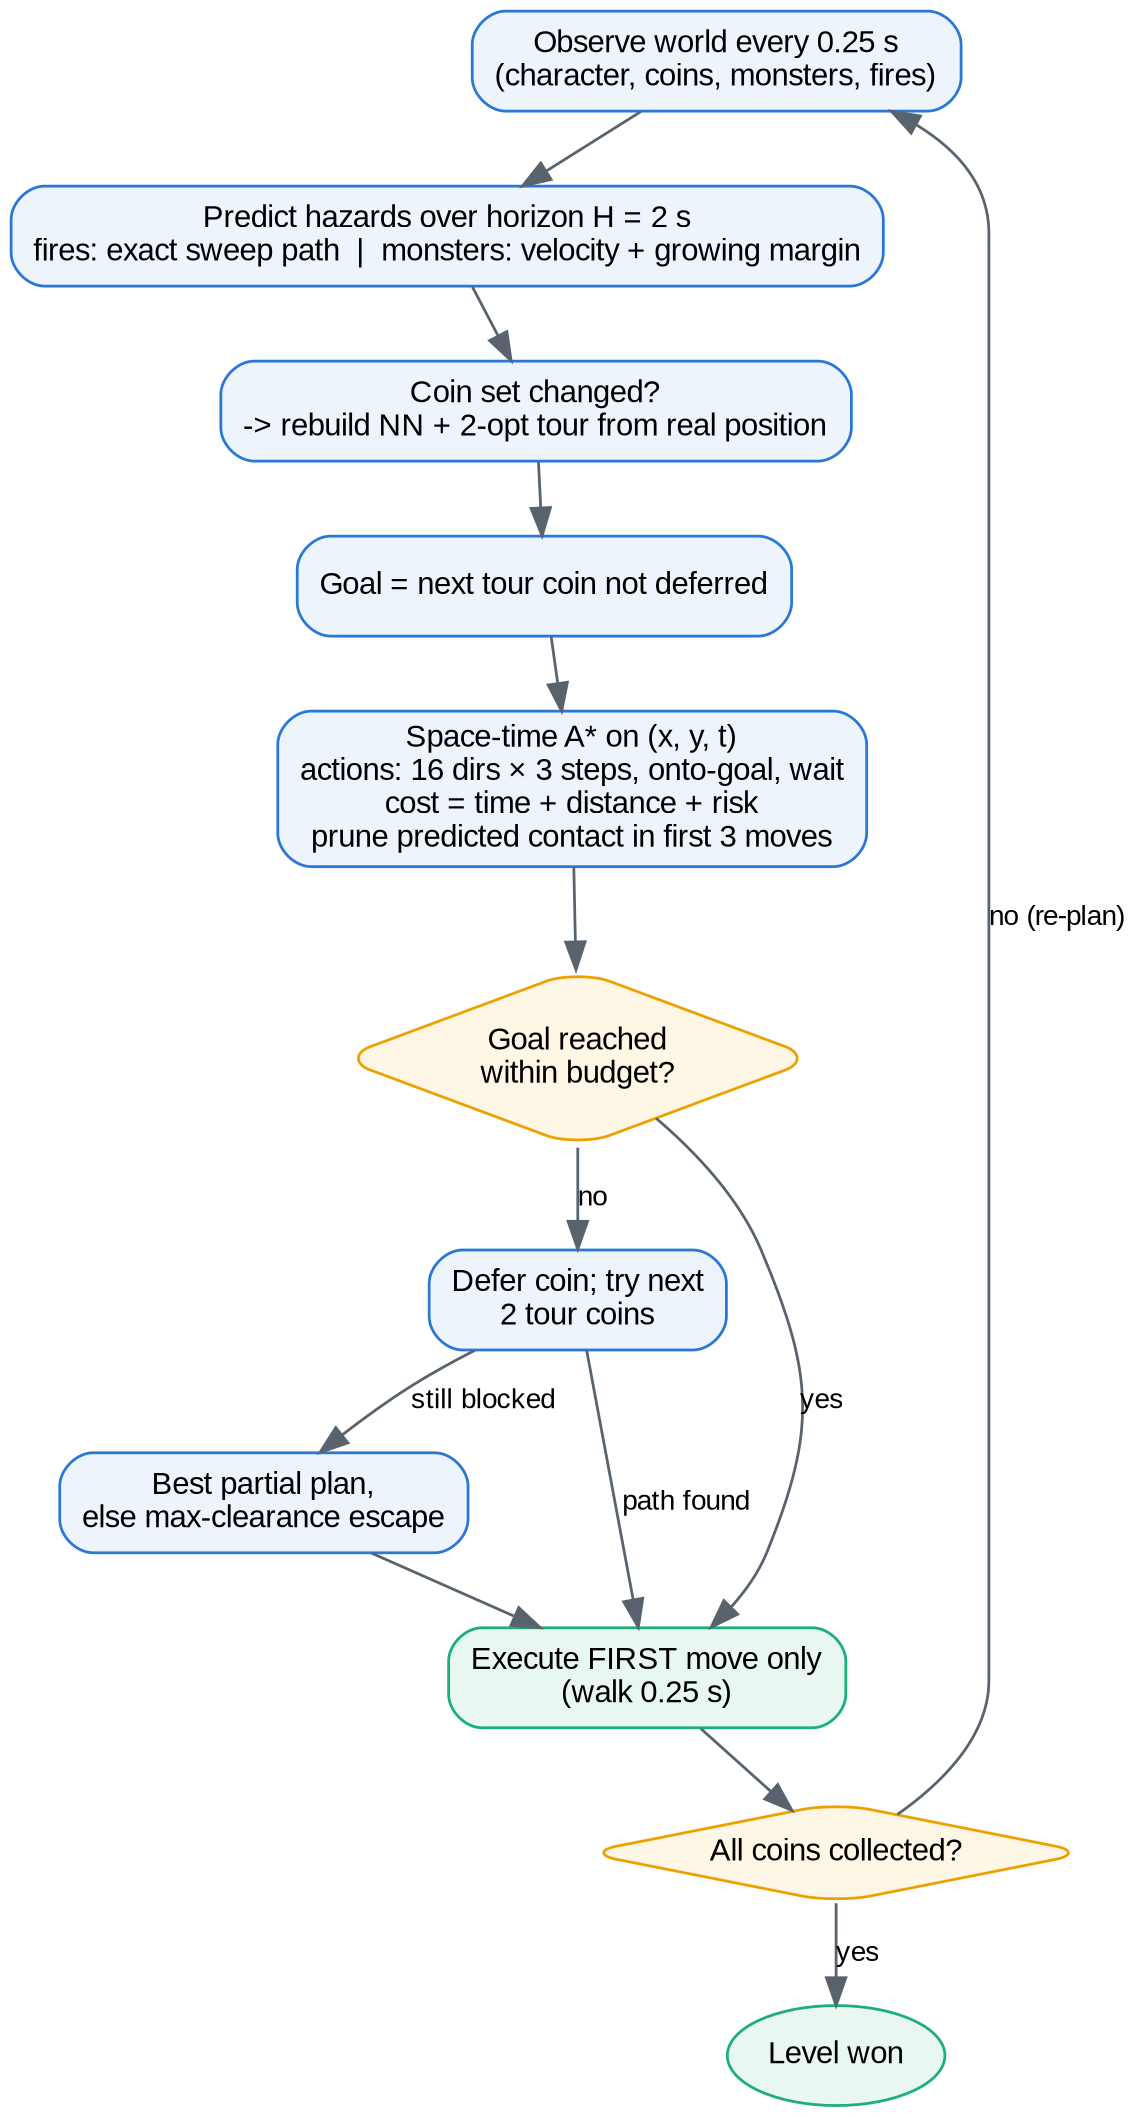

In [3]:
import graphviz
g = graphviz.Digraph('rhsta', format='png', graph_attr=dict(rankdir='TB', fontname='Helvetica', nodesep='0.35', ranksep='0.35', dpi='200'),
                     node_attr=dict(shape='box', style='rounded,filled', fillcolor='#eef4fc', color='#2a78d6', fontname='Helvetica', fontsize='11'),
                     edge_attr=dict(color='#59636e', fontname='Helvetica', fontsize='10'))
g.node('obs', 'Observe world every 0.25 s\n(character, coins, monsters, fires)')
g.node('pred', 'Predict hazards over horizon H = 2 s\nfires: exact sweep path  |  monsters: velocity + growing margin')
g.node('tour', 'Coin set changed?\n-> rebuild NN + 2-opt tour from real position', shape='box')
g.node('goal', 'Goal = next tour coin not deferred')
g.node('astar', 'Space-time A* on (x, y, t)\nactions: 16 dirs × 3 steps, onto-goal, wait\ncost = time + distance + risk\nprune predicted contact in first 3 moves')
g.node('found', 'Goal reached\nwithin budget?', shape='diamond', fillcolor='#fff7e6', color='#eda100')
g.node('alt', 'Defer coin; try next\n2 tour coins')
g.node('fb', 'Best partial plan,\nelse max-clearance escape')
g.node('exec', 'Execute FIRST move only\n(walk 0.25 s)', fillcolor='#e8f7f0', color='#1baf7a')
g.node('done', 'All coins collected?', shape='diamond', fillcolor='#fff7e6', color='#eda100')
g.node('end', 'Level won', shape='oval', fillcolor='#e8f7f0', color='#1baf7a')
g.edges([('obs', 'pred'), ('pred', 'tour'), ('tour', 'goal'), ('goal', 'astar'), ('astar', 'found')])
g.edge('found', 'exec', 'yes'); g.edge('found', 'alt', 'no'); g.edge('alt', 'fb', 'still blocked'); g.edge('alt', 'exec', 'path found')
g.edge('fb', 'exec'); g.edge('exec', 'done'); g.edge('done', 'end', 'yes'); g.edge('done', 'obs', 'no (re-plan)')
path = g.render(f'{OUT}/figures/rhsta_flowchart', cleanup=True)
display(Image(filename=path))

### Pseudo-code
```
every 0.25 s:
    obs = observe()
    HZ  = predict hazards for the next 8 moves        # fires exact, monsters v*t with margin
    if coins changed: tour = two_opt(nearest_neighbour(char, coins))
    for goal in the next 3 coins of the tour:
        path = A*(start = (char, t=0), goal,
                  moves = 16 directions x {1, 1/2, 1/4} * max_step, onto goal, wait,
                  cost  = 1 + 0.2*length + w*risk  (+ penalty for late contact),
                  not allowed: contact in the first 3 moves,
                  h     = max(0, dist_to_goal - coin_radius) / max_step)
        if path reaches goal: break
        skip this coin for 1 s
    if no path: use best partial path or escape move
    walk to path[0]
```

## 2. How good are the hazard predictions?
We expected the fire prediction to be exact. For monsters the error should grow the further ahead we
look, because a monster can pick a new random target at any time. That is why we use a margin that
grows with time (`monster_sigma`).

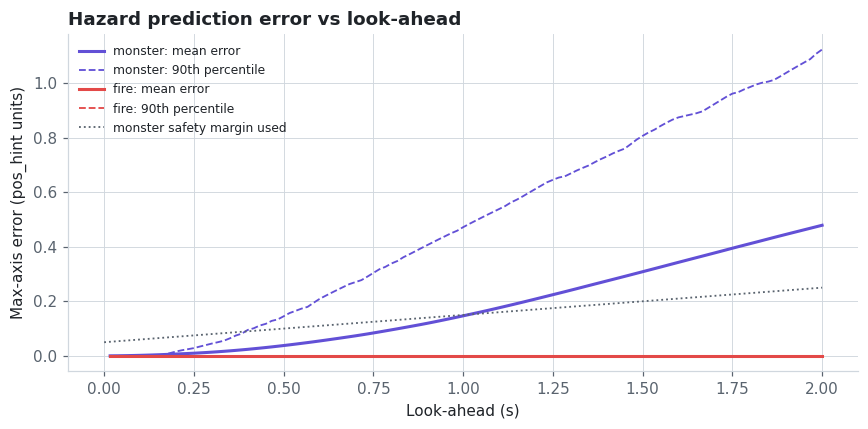

           count    mean     std  min  25%     50%     75%    max
kind                                                             
fire     66000.0  0.0000  0.0000  0.0  0.0  0.0000  0.0000  0.000
monster  46800.0  0.1818  0.2921  0.0  0.0  0.0179  0.2607  1.913


In [4]:
os.makedirs(f'{OUT}/prediction', exist_ok=True)
rows = []
rng = np.random.default_rng(0)
horizons = np.arange(1, 121)                       # frames ahead (2 s)
for level in LEVELS:
    for seed in range(10):
        env = sim.CoinTexSim(level, seed)
        env.run_frames(int(rng.integers(30, 600)))
        obs = env.observe()
        fut_m, fut_f = [], []
        for _ in horizons:
            env.step_frame()
            fut_m.append([m['pos'].copy() for m in env.monsters]); fut_f.append([f['pos'].copy() for f in env.fires])
        taus = horizons * sim.DT
        for j, (x, y, vx, vy) in enumerate(obs.monsters):
            pred = np.stack([x + vx * taus, y + vy * taus], 1)
            err = np.abs(pred - np.array([fm[j] for fm in fut_m])).max(1)
            rows += [dict(kind='monster', level=level, tau=t, err=e) for t, e in zip(taus, err)]
        for j, f in enumerate(obs.fires):
            err = np.abs(_fire_positions(f, taus) - np.array([ff[j] for ff in fut_f])).max(1)
            rows += [dict(kind='fire', level=level, tau=t, err=e) for t, e in zip(taus, err)]
pe = pd.DataFrame(rows)
pe.to_csv(f'{OUT}/prediction/prediction_errors.csv', index=False)
agg = pe.groupby(['kind', 'tau']).err.agg(['mean', lambda s: s.quantile(0.9)]).reset_index()
agg.columns = ['kind', 'tau', 'mean', 'p90']
fig, ax = plt.subplots(figsize=(8, 4))
for kind, col in [('monster', '#6250d6'), ('fire', '#e34948')]:
    a = agg[agg.kind == kind]
    ax.plot(a.tau, a['mean'], color=col, lw=2, label=f'{kind}: mean error')
    ax.plot(a.tau, a['p90'], color=col, lw=1.2, ls='--', label=f'{kind}: 90th percentile')
t = np.linspace(0, 2, 50)
ax.plot(t, DEFAULT.monster_margin + DEFAULT.monster_sigma * t, color='#59636e', lw=1.2, ls=':', label='monster safety margin used')
ax.set_xlabel('Look-ahead (s)'); ax.set_ylabel('Max-axis error (pos_hint units)')
ax.set_title('Hazard prediction error vs look-ahead', loc='left'); ax.legend(fontsize=8)
fig.tight_layout(); plots.save(fig, f'{OUT}/figures', 'prediction_error.png'); plt.show()
print(pe.groupby('kind').err.describe().round(4))

## 3. What one plan looks like
The blue line is the plan. The dotted red lines are where the fires will move during the plan.

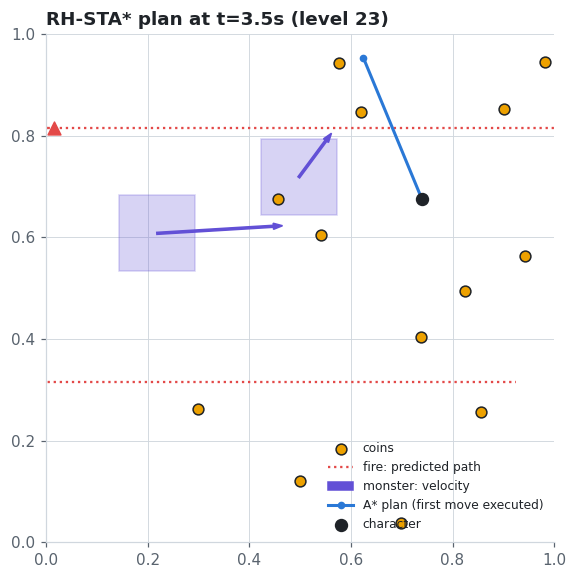

In [5]:
level, seed = 23, 0
env = sim.CoinTexSim(level, seed)
agent = ProposedAgent(seed)
for _ in range(14):                                 # play a few moves to reach an interesting state
    tgt, wait = agent.act(env.observe()); env.command(tgt); env.run_frames(wait)
obs = env.observe(); agent.act(obs)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*np.array(obs.coins).T, c='#eda100', edgecolors=plots.INK, s=50, label='coins', zorder=3)
taus = np.linspace(0, DEFAULT.horizon * sim.MOVE_SECONDS, 60)
for i, f in enumerate(obs.fires):
    p = _fire_positions(f, taus); ax.plot(p[:, 0], p[:, 1], ':', color='#e34948', lw=1.5, label='fire: predicted path' if i == 0 else None)
    ax.scatter(f.x, f.y, marker='^', c='#e34948', s=70, zorder=3)
for i, (x, y, vx, vy) in enumerate(obs.monsters):
    ax.add_patch(plt.Rectangle((x - sim.MONSTER_GAB, y - sim.MONSTER_GAB), 2 * sim.MONSTER_GAB, 2 * sim.MONSTER_GAB, color='#6250d6', alpha=.25))
    ax.arrow(x, y, vx * 0.5, vy * 0.5, color='#6250d6', width=0.004, label='monster: velocity' if i == 0 else None)
plan = np.array([obs.char] + list(agent.last_plan))
ax.plot(plan[:, 0], plan[:, 1], '-o', color=plots.color('proposed'), lw=2, ms=4, label='A* plan (first move executed)')
ax.scatter(*obs.char, c=plots.INK, s=60, zorder=4, label='character')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.legend(fontsize=8, loc='lower right')
ax.set_title(f'RH-STA* plan at t={obs.time:.1f}s (level {level})', loc='left')
plots.save(fig, f'{OUT}/figures', 'plan_snapshot.png'); plt.show()

{'level': 23, 'seed': 0, 'agent': 'proposed', 'hazard_speed': 1.0, 'won': 1, 'died': 0, 'timeout': 0, 'coins_total': 25, 'coins_collected': 25, 'coin_pct': 100.0, 'seconds': 7.45, 'completion_time': 7.45, 'remaining_life': 100.0, 'monster_hit_frames': 0, 'fire_hit_frames': 0, 'near_miss_pct': 7.38, 'path_length': 6.033, 'racr': 3.3557, 'decisions': 30, 'mean_plan_ms': 5.4, 'max_plan_ms': 34.115, 'wall_seconds': 0.185}


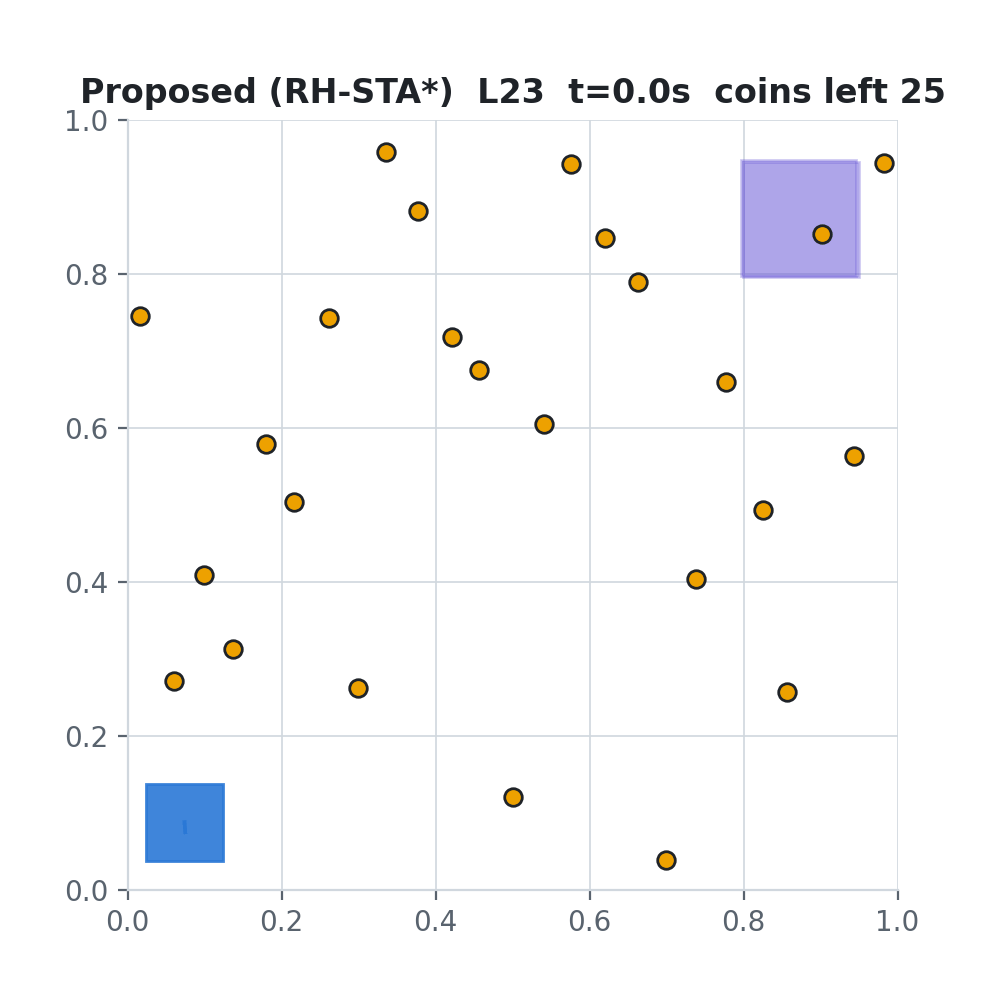

In [6]:
row, trace = runner.play_episode(23, 0, 'proposed', record=True)
print(row)
gif = plots.animate_episode(trace, 'proposed', f'{OUT}/figures/proposed_L23_s0.gif')
display(Image(filename=gif))

## 4. Main run - all 24 levels

In [7]:
CSV = f'{OUT}/main_per_run.csv'
runner.reset_if_changed(CSV, runner.proposed_code_tag())
runner.run_sweep(CSV, LEVELS, SEEDS, ['proposed'], workers=WORKERS)
df = pd.read_csv(CSV)
log_run('02_proposed_main', episodes=len(df))
overall = runner.summarise(df); per_level = runner.summarise(df, by=('agent', 'level'))
overall.to_csv(f'{OUT}/tables/overall_summary.csv', index=False)
per_level.to_csv(f'{OUT}/tables/per_level_summary.csv', index=False)
display(overall.round(2))
display(per_level[['level', 'success_rate', 'death_rate', 'completion_time_mean', 'remaining_life_mean',
                   'near_miss_pct_mean', 'plan_ms_mean']].round(2))

0 episodes already in main_per_run.csv; running 1200 more
  60/1200 episodes  (162.88/s, ETA 0.1 min)
  120/1200 episodes  (177.92/s, ETA 0.1 min)
  180/1200 episodes  (174.54/s, ETA 0.1 min)
  240/1200 episodes  (163.45/s, ETA 0.1 min)
  300/1200 episodes  (153.44/s, ETA 0.1 min)
  360/1200 episodes  (144.95/s, ETA 0.1 min)
  420/1200 episodes  (140.97/s, ETA 0.1 min)
  480/1200 episodes  (133.93/s, ETA 0.1 min)
  540/1200 episodes  (127.49/s, ETA 0.1 min)
  600/1200 episodes  (126.17/s, ETA 0.1 min)
  660/1200 episodes  (123.12/s, ETA 0.1 min)
  720/1200 episodes  (119.43/s, ETA 0.1 min)
  780/1200 episodes  (110.79/s, ETA 0.1 min)
  840/1200 episodes  (111.55/s, ETA 0.1 min)
  900/1200 episodes  (103.15/s, ETA 0.0 min)
  960/1200 episodes  (103.02/s, ETA 0.0 min)
  1020/1200 episodes  (101.01/s, ETA 0.0 min)
  1080/1200 episodes  (96.26/s, ETA 0.0 min)
  1140/1200 episodes  (93.22/s, ETA 0.0 min)
  1200/1200 episodes  (88.12/s, ETA 0.0 min)


,agent,episodes,success_rate,death_rate,timeout_rate,avg_coin_pct,completion_time_mean,completion_time_median,episode_time_mean,remaining_life_mean,near_miss_pct_mean,racr_mean,path_length_mean,plan_ms_mean
0,proposed,1200,100.0,0.0,0.0,100.0,4.3,4.22,4.3,99.52,3.2,3.18,3.4,5.89


,level,success_rate,death_rate,completion_time_mean,remaining_life_mean,near_miss_pct_mean,plan_ms_mean
0,1,100.0,0.0,1.94,100.00,0.74,4.40
1,2,100.0,0.0,2.77,100.00,0.63,3.99
2,3,100.0,0.0,3.74,99.20,1.27,3.46
3,4,100.0,0.0,3.32,100.00,0.82,5.09
4,5,100.0,0.0,4.42,98.20,1.68,3.81
5,6,100.0,0.0,3.72,99.90,1.30,4.67
6,7,100.0,0.0,3.53,99.44,2.64,6.53
7,8,100.0,0.0,4.57,99.20,1.84,4.09
8,9,100.0,0.0,3.84,100.00,1.90,5.02
9,10,100.0,0.0,4.51,98.53,3.19,6.55


### Planning time in the real game
The times in the sweep above are measured while several episodes run in parallel, so they are higher
than in the real game, where only one planner runs. Here we time one episode at a time on the hardest levels.

In [8]:
rows = [runner.play_episode(lv, s, 'proposed') for lv in (18, 21, 22, 24) for s in range(10)]
t = pd.DataFrame(rows)[['level', 'seed', 'mean_plan_ms', 'max_plan_ms']]
t.to_csv(f'{OUT}/tables/planning_time_single.csv', index=False)
print(f"mean plan time {t.mean_plan_ms.mean():.1f} ms | worst single plan {t.max_plan_ms.max():.1f} ms "
      f"| 95th percentile of worst {t.max_plan_ms.quantile(.95):.1f} ms  (one move = 250 ms)")

mean plan time 4.8 ms | worst single plan 44.4 ms | 95th percentile of worst 42.9 ms  (one move = 250 ms)


## 5. Ablation - which parts matter?
We turn off one part at a time: hazards completely, hazard movement prediction (hazards treated as
not moving), and the 2-opt tour (just go to the nearest coin).

0 episodes already in ablation_per_run.csv; running 3600 more
  180/3600 episodes  (199.22/s, ETA 0.3 min)
  360/3600 episodes  (210.89/s, ETA 0.3 min)
  540/3600 episodes  (197.81/s, ETA 0.3 min)
  720/3600 episodes  (181.28/s, ETA 0.3 min)
  900/3600 episodes  (170.62/s, ETA 0.3 min)
  1080/3600 episodes  (154.03/s, ETA 0.3 min)
  1260/3600 episodes  (148.82/s, ETA 0.3 min)
  1440/3600 episodes  (141.93/s, ETA 0.3 min)
  1620/3600 episodes  (135.35/s, ETA 0.2 min)
  1800/3600 episodes  (134.07/s, ETA 0.2 min)
  1980/3600 episodes  (131.01/s, ETA 0.2 min)
  2160/3600 episodes  (129.01/s, ETA 0.2 min)
  2340/3600 episodes  (122.16/s, ETA 0.2 min)
  2520/3600 episodes  (121.75/s, ETA 0.1 min)
  2700/3600 episodes  (114.75/s, ETA 0.1 min)
  2880/3600 episodes  (115.19/s, ETA 0.1 min)
  3060/3600 episodes  (112.91/s, ETA 0.1 min)
  3240/3600 episodes  (108.45/s, ETA 0.1 min)
  3420/3600 episodes  (105.14/s, ETA 0.0 min)
  3600/3600 episodes  (100.83/s, ETA 0.0 min)


,agent,success_rate,death_rate,completion_time_mean,remaining_life_mean,near_miss_pct_mean,racr_mean,path_length_mean
0,proposed,100.00,0.00,4.30,99.52,3.20,3.18,3.40
1,proposed_no_hazard,92.08,7.92,3.88,67.71,7.36,2.31,2.89
2,proposed_static_hazard,99.75,0.25,4.41,92.67,4.90,2.91,3.54
3,proposed_no_tour,100.00,0.00,4.43,99.63,3.50,3.10,3.49


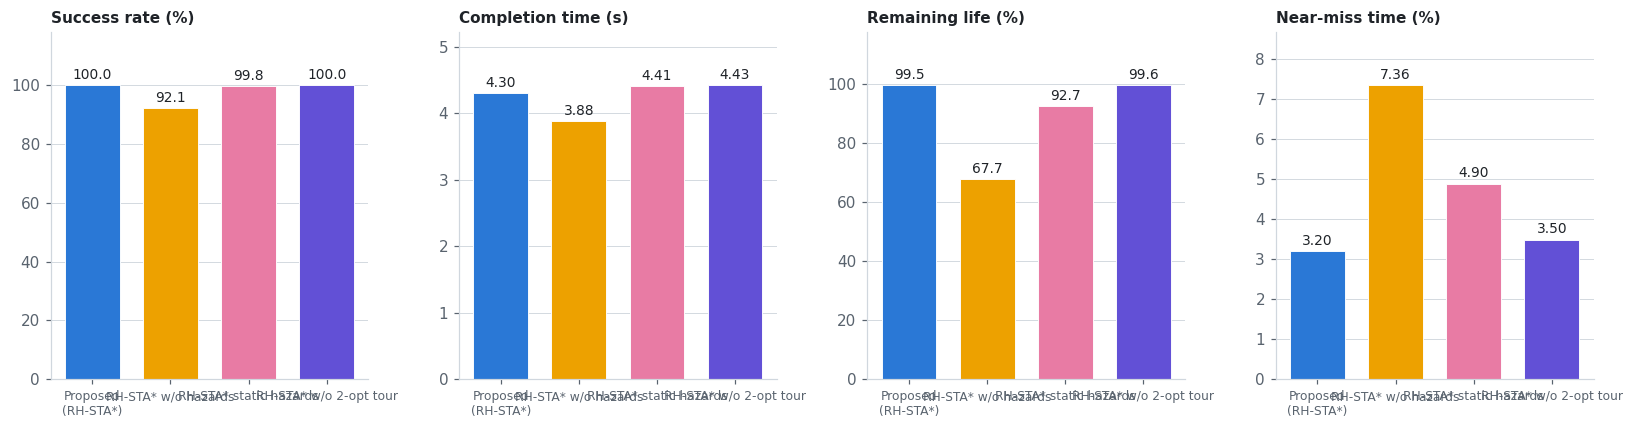

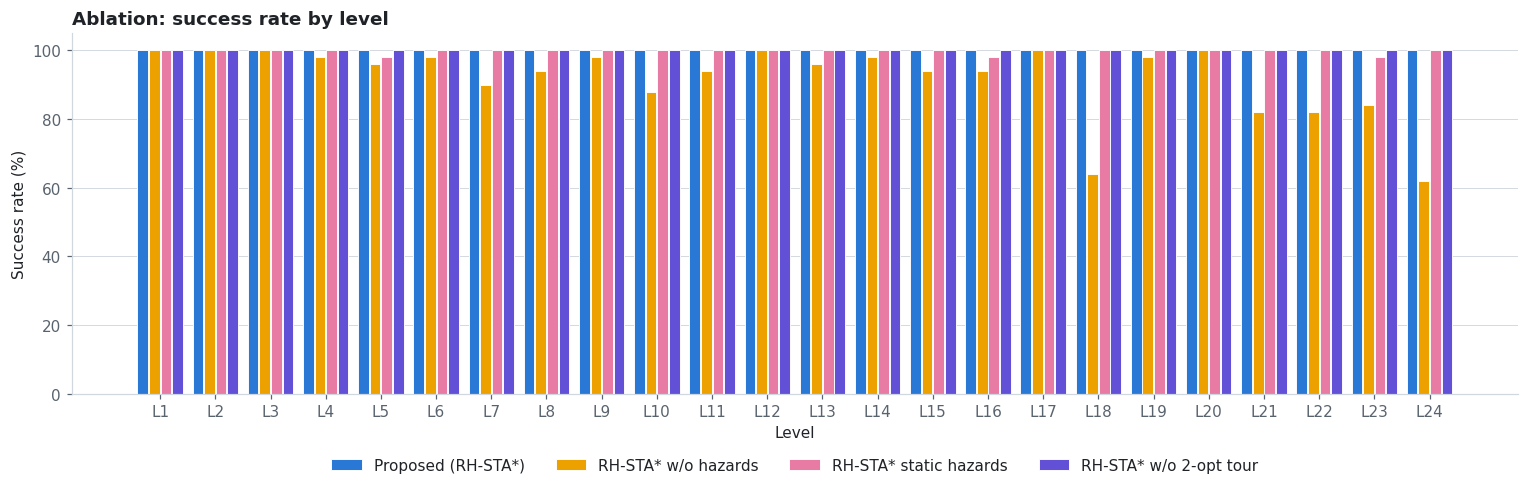

In [9]:
ABL = ['proposed_no_hazard', 'proposed_static_hazard', 'proposed_no_tour']
CSV_A = f'{OUT}/ablation_per_run.csv'
runner.reset_if_changed(CSV_A, runner.proposed_code_tag())
runner.run_sweep(CSV_A, LEVELS, SEEDS, ABL, workers=WORKERS)
abl = pd.concat([df, pd.read_csv(CSV_A)], ignore_index=True)
log_run('02_proposed_ablation', episodes=len(abl))
order = ['proposed'] + ABL
abl_sum = runner.summarise(abl).set_index('agent').loc[order].reset_index()
abl_sum.to_csv(f'{OUT}/tables/ablation_summary.csv', index=False)
display(abl_sum[['agent', 'success_rate', 'death_rate', 'completion_time_mean', 'remaining_life_mean',
                 'near_miss_pct_mean', 'racr_mean', 'path_length_mean']].round(2))
fig = plots.overall_bars(abl_sum, ['success_rate', 'completion_time_mean', 'remaining_life_mean', 'near_miss_pct_mean'], order,
                         ['Success rate (%)', 'Completion time (s)', 'Remaining life (%)', 'Near-miss time (%)'],
                         fmts=['%.1f', '%.2f', '%.1f', '%.2f'], figsize=(15, 4))
plots.save(fig, f'{OUT}/figures', 'ablation_overall.png'); plt.show()
fig = plots.per_level_bars(abl, 'won', order, 'Success rate (%)', 'Ablation: success rate by level', scale=100, ylim=(0, 105))
plots.save(fig, f'{OUT}/figures', 'ablation_success_by_level.png'); plt.show()

## 6. Sensitivity - changing the parameters
Only on the hard levels to save time.
- `max_step`: longer moves are faster but harder to control
- `horizon`: how far ahead A* looks
- `risk_weight`: how much near misses are avoided
- `monster_sigma`: how fast the monster margin grows

0 episodes already in sensitivity_per_run.csv; running 4600 more
  230/4600 episodes  (73.52/s, ETA 1.0 min)
  460/4600 episodes  (85.55/s, ETA 0.8 min)
  690/4600 episodes  (80.29/s, ETA 0.8 min)
  920/4600 episodes  (80.37/s, ETA 0.8 min)
  1150/4600 episodes  (79.29/s, ETA 0.7 min)
  1380/4600 episodes  (79.64/s, ETA 0.7 min)
  1610/4600 episodes  (75.19/s, ETA 0.7 min)
  1840/4600 episodes  (73.73/s, ETA 0.6 min)
  2070/4600 episodes  (70.51/s, ETA 0.6 min)
  2300/4600 episodes  (68.70/s, ETA 0.6 min)
  2530/4600 episodes  (64.51/s, ETA 0.5 min)
  2760/4600 episodes  (61.94/s, ETA 0.5 min)
  2990/4600 episodes  (62.01/s, ETA 0.4 min)
  3220/4600 episodes  (61.92/s, ETA 0.4 min)
  3450/4600 episodes  (61.52/s, ETA 0.3 min)
  3680/4600 episodes  (60.08/s, ETA 0.3 min)
  3910/4600 episodes  (60.05/s, ETA 0.2 min)
  4140/4600 episodes  (59.57/s, ETA 0.1 min)
  4370/4600 episodes  (58.31/s, ETA 0.1 min)
  4600/4600 episodes  (57.17/s, ETA 0.0 min)


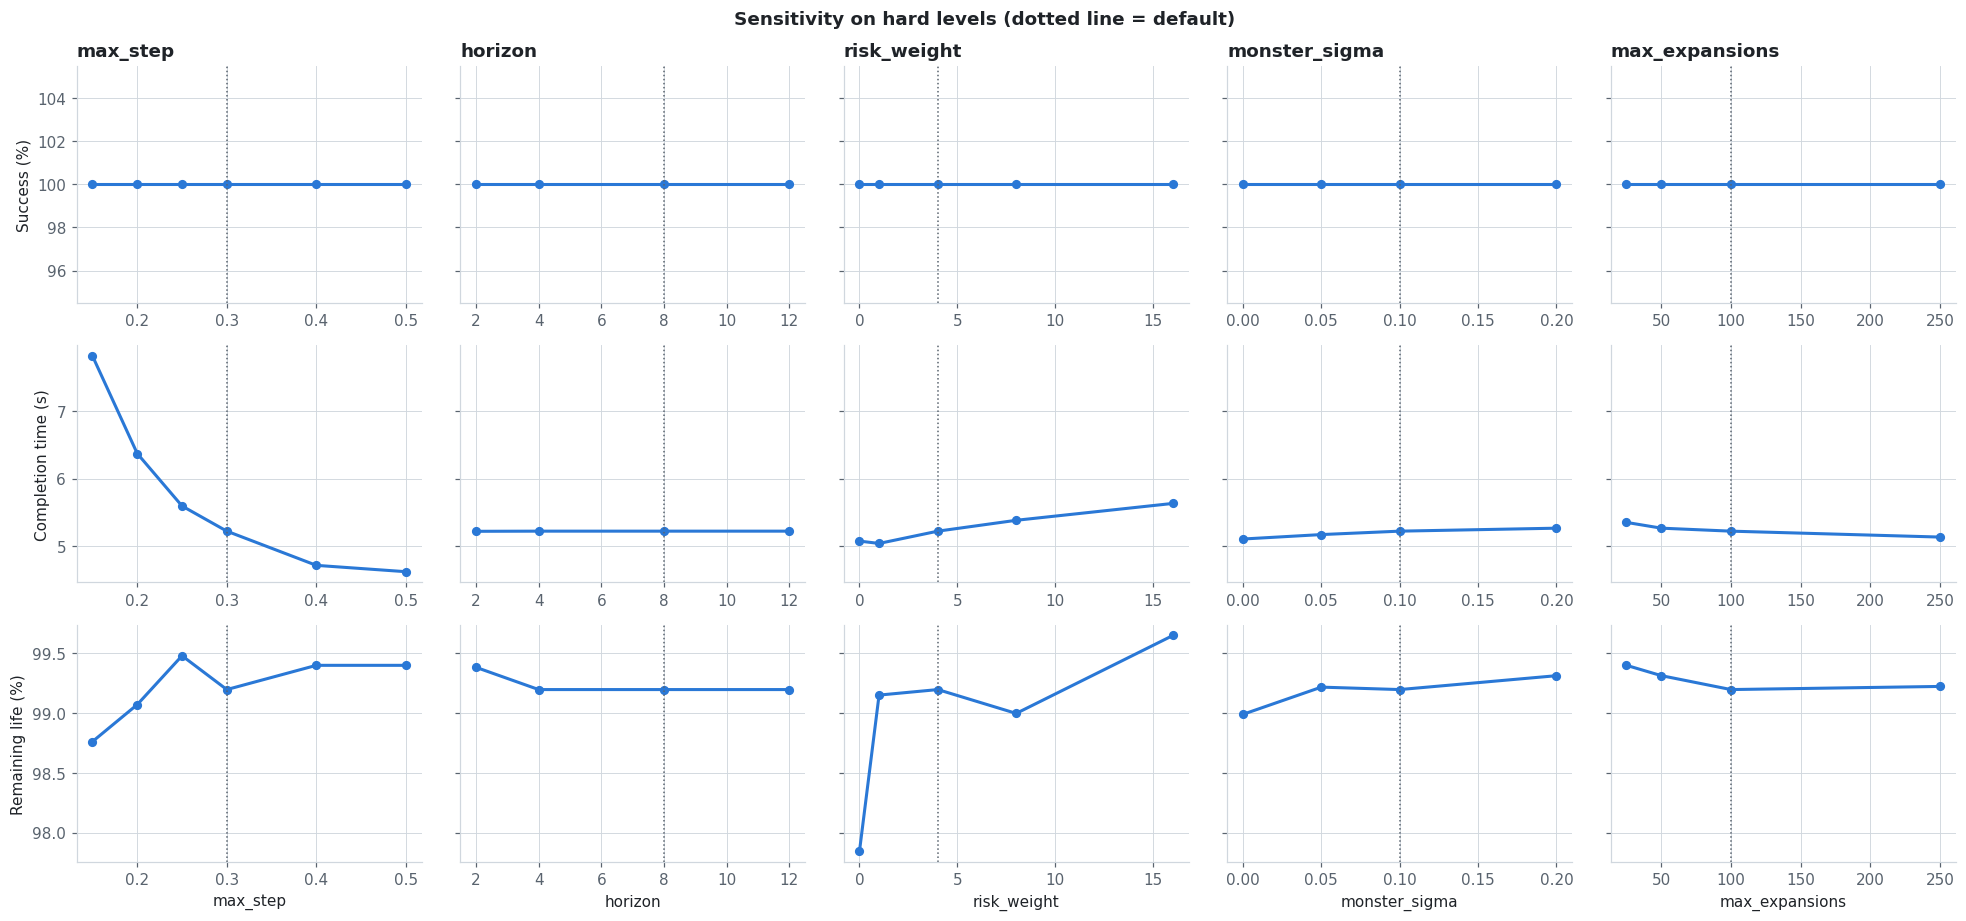

,param,value,success,time,life
0,horizon,2.00,100.0,5.22,99.38
1,horizon,4.00,100.0,5.22,99.20
2,horizon,8.00,100.0,5.22,99.20
3,horizon,12.00,100.0,5.22,99.20
4,max_expansions,25.00,100.0,5.35,99.40
5,max_expansions,50.00,100.0,5.27,99.31
6,max_expansions,100.00,100.0,5.22,99.20
7,max_expansions,250.00,100.0,5.14,99.22
8,max_step,0.15,100.0,7.81,98.76
9,max_step,0.20,100.0,6.37,99.07


In [10]:
GRID = {'max_step': [0.15, 0.20, 0.25, 0.30, 0.40, 0.50],
        'horizon': [2, 4, 8, 12],
        'risk_weight': [0.0, 1.0, 4.0, 8.0, 16.0],
        'monster_sigma': [0.0, 0.05, 0.10, 0.20],
        'max_expansions': [25, 50, 100, 250]}
SENS = {f'{p}={v}': replace(DEFAULT, name=f'{p}={v}', **{p: v}) for p, vals in GRID.items() for v in vals}
CSV_S = f'{OUT}/sensitivity_per_run.csv'
runner.reset_if_changed(CSV_S, runner.proposed_code_tag())
runner.run_sweep(CSV_S, CFG['hard_levels'], range(CFG['sensitivity_seeds']), [], configs=SENS, workers=WORKERS)
sens = pd.read_csv(CSV_S)
log_run('02_proposed_sensitivity', episodes=len(sens))
sens[['param', 'value']] = sens.agent.str.split('=', expand=True); sens['value'] = sens.value.astype(float)
ss = sens.groupby(['param', 'value']).agg(success=('won', lambda s: 100 * s.mean()), time=('completion_time', 'mean'),
                                         life=('remaining_life', 'mean')).reset_index()
ss.to_csv(f'{OUT}/tables/sensitivity_summary.csv', index=False)
fig, axes = plt.subplots(3, 5, figsize=(18, 8.5), sharey='row')
for j, p in enumerate(GRID):
    s = ss[ss.param == p]
    for i, (col, ylab) in enumerate([('success', 'Success (%)'), ('time', 'Completion time (s)'), ('life', 'Remaining life (%)')]):
        ax = axes[i, j]; ax.plot(s.value, s[col], '-o', color=plots.color('proposed'), lw=2, ms=5)
        ax.axvline(getattr(DEFAULT, p), color=plots.MUTED, ls=':', lw=1)
        if j == 0: ax.set_ylabel(ylab)
        if i == 2: ax.set_xlabel(p)
        if i == 0: ax.set_title(p, loc='left')
fig.suptitle('Sensitivity on hard levels (dotted line = default)', fontweight='bold'); fig.tight_layout()
plots.save(fig, f'{OUT}/figures', 'sensitivity.png'); plt.show()
display(ss.round(2))

In [11]:
headline = {
    'agent': 'proposed', 'config': asdict(DEFAULT), 'episodes': int(len(df)),
    'success_rate_pct': round(100 * df.won.mean(), 2),
    'levels_always_won': int((df.groupby('level').won.mean() == 1).sum()),
    'completion_time_mean_s': round(df.completion_time.mean(), 2),
    'remaining_life_mean_pct': round(df.remaining_life.mean(), 2),
    'plan_ms_mean': round(df.mean_plan_ms.mean(), 2), 'plan_ms_max': round(df.max_plan_ms.max(), 2),
    'ablation': abl_sum[['agent', 'success_rate', 'completion_time_mean', 'remaining_life_mean']].round(2).to_dict('records'),
}
json.dump(headline, open(f'{OUT}/headline.json', 'w'), indent=2)
headline

{'agent': 'proposed',
 'config': {'name': 'proposed',
  'max_step': 0.3,
  'step_fracs': (1.0, 0.5, 0.25),
  'n_dirs': 16,
  'horizon': 8,
  'max_expansions': 100,
  'heuristic_weight': 1.2,
  'samples': 8,
  'grid': 0.02,
  'use_hazards': True,
  'predict_motion': True,
  'monster_margin': 0.05,
  'fire_margin': 0.035,
  'monster_sigma': 0.1,
  'contact_buffer': 0.01,
  'hard_steps': 3,
  'late_contact_penalty': 3.0,
  'risk_weight': 4.0,
  'dist_weight': 0.2,
  'use_tour': True,
  'two_opt': True,
  'alt_goals': 3,
  'defer_seconds': 1.0,
  'stuck_seconds': 4.0,
  'stagnation_relax': 0.25},
 'episodes': 1200,
 'success_rate_pct': np.float64(100.0),
 'levels_always_won': 24,
 'completion_time_mean_s': np.float64(4.3),
 'remaining_life_mean_pct': np.float64(99.52),
 'plan_ms_mean': np.float64(5.89),
 'plan_ms_max': 191.55,
 'ablation': [{'agent': 'proposed',
   'success_rate': 100.0,
   'completion_time_mean': 4.3,
   'remaining_life_mean': 99.52},
  {'agent': 'proposed_no_hazard',
   